# Analysis of times it takes for packets to reach from NIC to Application in a regular networking app using OpenOnload.

## Experiment setup

Trading day: *30 Jan 2019*

High packet rate time window: *15:59:59–16:00:01*

Low packet rate time window: *14:59:00–15:00:03*

We will use run our program with OpenOnload library that will speed up network calss to send and receive packets. NIC is hardware timestamping capable, which gives us the ability to measure the time it takes for packets to reach from NIC to Application. We conduct 15 runs for every system configuration. The configuration space is comprised of choices on OS settings (Default/Low latency tuned) and replay duration (2s and 63s), so 4 configurations in total. Note that for every configuration, the number of packets sent is approximately the same $\approx 18000$, so replay duration directly translates to higher and lower packet rates.

### Imports

In [1]:
import re

import itertools
import numpy as np
from pathlib import Path
from enum import Enum, auto
from analysis.utils import report_metrics, generate_percentiles, plot_percentiles

### Load data

In [2]:
class OS(Enum):
    DEFAULT = auto()
    LOW_LATENCY = auto()
class PacketRate(Enum):
    HIGH = auto()
    LOW = auto()
class TsType(Enum):
    NIC = auto()
    APP = auto()

In [3]:
def natural_sort_key(path):
    return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', path.name)]

In [4]:
kernel_latency_folder = '/home/illia-derevianko/Projects/nanoparser/analysis/kernel_latency_onload'
tuning_folders = {OS.LOW_LATENCY: 'tuning', OS.DEFAULT: 'no_tuning'}
packet_rate_folders = {PacketRate.HIGH: 'high_packet_rate', PacketRate.LOW: 'low_packet_rate'}
filename_pattern = {TsType.NIC: r'^rx_times\d+', TsType.APP: r'^receive_app_times\d+'}

data: dict[tuple[OS, PacketRate, TsType], np.ndarray] = dict()

for config in itertools.product(OS, PacketRate, TsType):
    os_type, packet_rate, ts_type = config
    dir_path = Path(kernel_latency_folder) / tuning_folders[os_type] / packet_rate_folders[packet_rate]
    pattern = re.compile(filename_pattern[ts_type])
    target_files = sorted([f for f in dir_path.iterdir() if f.is_file() and pattern.match(f.name)], key=natural_sort_key)

    if target_files:
        print(f"Loading {len(target_files)} files for {os_type.name}, {packet_rate.name}, {ts_type.name}")
        file_arrays = [np.fromfile(f, dtype=np.uint64) for f in target_files]
        data[config] = np.array(file_arrays)
    else:
        print(f"Warning: No match found for {os_type.name}, {packet_rate.name}, {ts_type.name} in {dir_path}")

Loading 15 files for DEFAULT, HIGH, NIC
Loading 15 files for DEFAULT, HIGH, APP
Loading 15 files for DEFAULT, LOW, NIC
Loading 15 files for DEFAULT, LOW, APP
Loading 15 files for LOW_LATENCY, HIGH, NIC
Loading 15 files for LOW_LATENCY, HIGH, APP
Loading 15 files for LOW_LATENCY, LOW, NIC
Loading 15 files for LOW_LATENCY, LOW, APP


In [5]:
def timestamp_diff(minuend, subtrahend):
    assert minuend.shape == subtrahend.shape
    assert minuend.dtype == subtrahend.dtype
    assert (minuend > subtrahend).all()
    return minuend - subtrahend

## Comparison (OS tuned for low latency vs default)

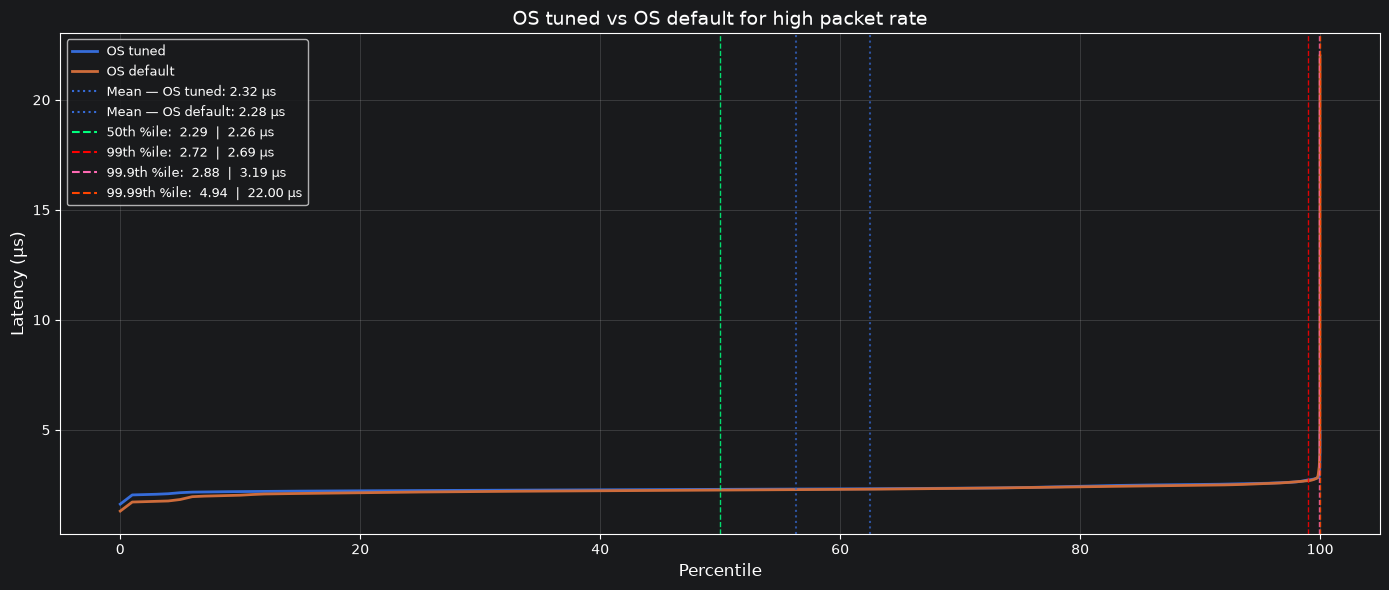

In [6]:
latencies_tuned_high_rate = timestamp_diff(data[(OS.LOW_LATENCY, PacketRate.HIGH, TsType.APP)],
                   data[(OS.LOW_LATENCY, PacketRate.HIGH, TsType.NIC)]).flatten() / 1000

latencies_default_high_rate = timestamp_diff(data[(OS.DEFAULT, PacketRate.HIGH, TsType.APP)],
                     data[(OS.DEFAULT, PacketRate.HIGH, TsType.NIC)]).flatten() / 1000

plot_percentiles(
    (latencies_tuned_high_rate, "OS tuned"),
    (latencies_default_high_rate, "OS default"),
    percentiles=generate_percentiles(99.99),
    xlabel="Percentile",
    ylabel="Latency (µs)",
    title="OS tuned vs OS default for high packet rate")

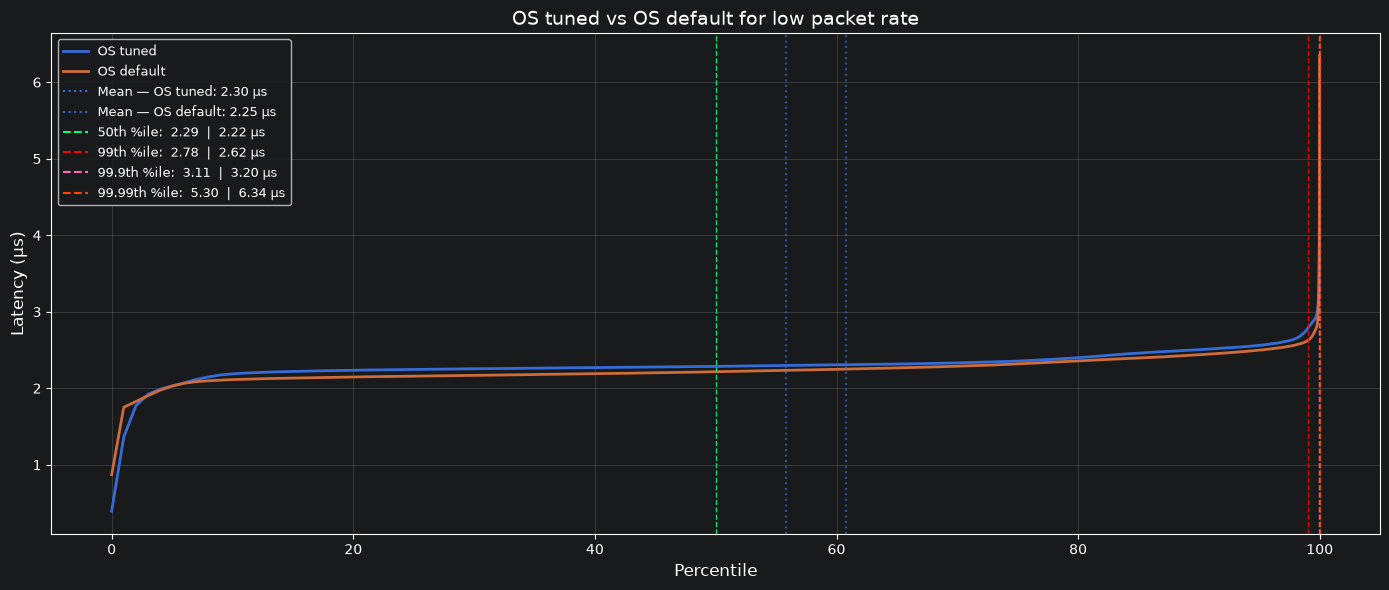

In [7]:
latencies_tuned_low_rate = timestamp_diff(data[(OS.LOW_LATENCY, PacketRate.LOW, TsType.APP)],
                            data[(OS.LOW_LATENCY, PacketRate.LOW, TsType.NIC)]).flatten() / 1000
latencies_default_low_rate = timestamp_diff(data[(OS.DEFAULT, PacketRate.LOW, TsType.APP)],
                              data[(OS.DEFAULT, PacketRate.LOW, TsType.NIC)]).flatten() / 1000

plot_percentiles(
    (latencies_tuned_low_rate, "OS tuned"),
    (latencies_default_low_rate, "OS default"),
    percentiles=generate_percentiles(99.99),
    xlabel="Percentile",
    ylabel="Latency (µs)",
    title="OS tuned vs OS default for low packet rate")

## Comparison (Low vs high packet rate)

(282240,)


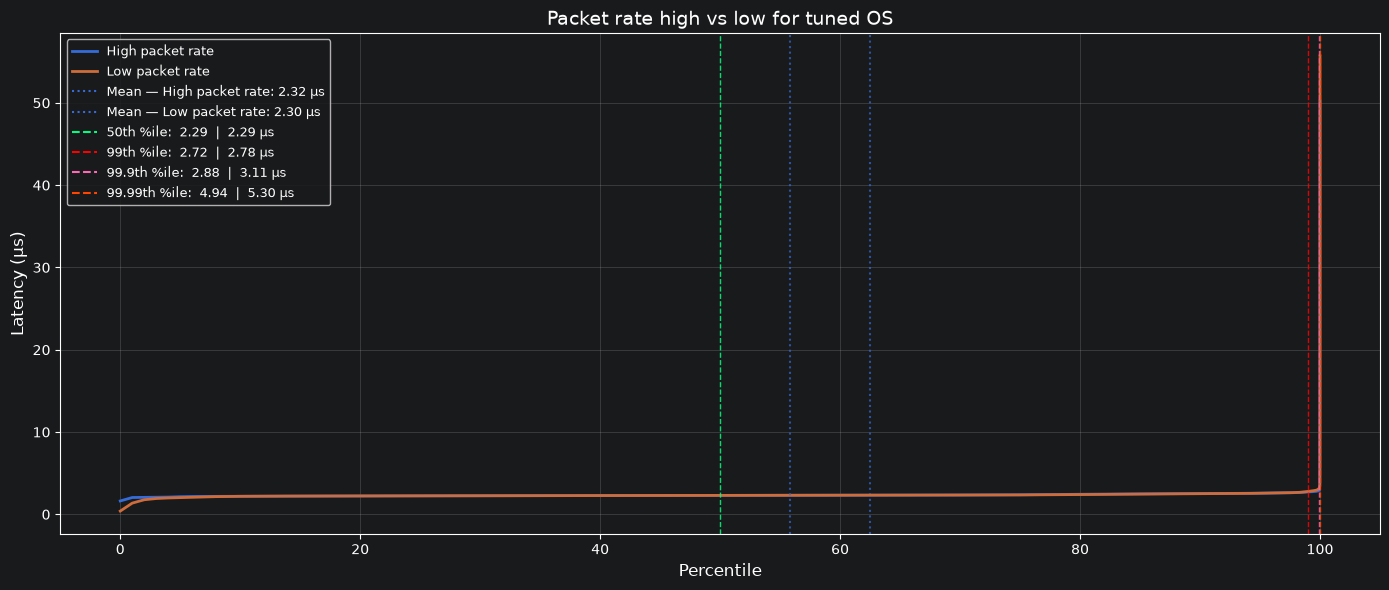

In [8]:
plot_percentiles(
    (latencies_tuned_high_rate, "High packet rate"),
    (latencies_tuned_low_rate, "Low packet rate"),
    percentiles=generate_percentiles(100),
    xlabel="Percentile",
    ylabel="Latency (µs)",
    title="Packet rate high vs low for tuned OS")

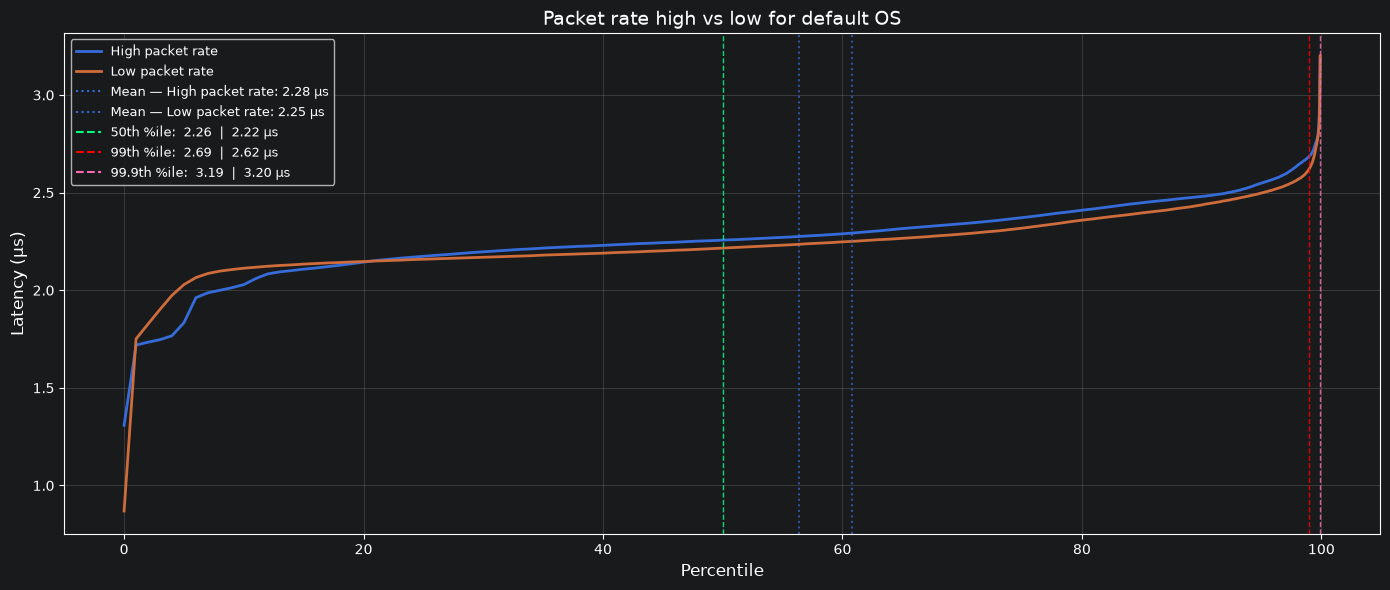

In [9]:
plot_percentiles(
    (latencies_default_high_rate, "High packet rate"),
    (latencies_default_low_rate, "Low packet rate"),
    percentiles=generate_percentiles(99.9),
    xlabel="Percentile",
    ylabel="Latency (µs)",
    title="Packet rate high vs low for default OS")

## Summary tuned OS

In [10]:
report_metrics(latencies_tuned_high_rate, "Tuned OS high packet rate")
report_metrics(latencies_tuned_low_rate, "Tuned OS low packet rate")

=== Tuned OS high packet rate ===
Count     : 282,240
Min       : 1.624
Max       : 50.227
Mean      : 2.323
Std Dev   : 0.306
P50 (Med) : 2.288
P90       : 2.517
P99       : 2.724
P99.9     : 2.884
P99.99    : 4.935

=== Tuned OS low packet rate ===
Count     : 280,740
Min       : 0.395
Max       : 55.711
Mean      : 2.297
Std Dev   : 0.321
P50 (Med) : 2.286
P90       : 2.504
P99       : 2.783
P99.9     : 3.112
P99.99    : 5.301



## Summary default OS

todo: absolute min/max, grand mean, polled variance, mean and std of tails
plot chronological stability

In [11]:
report_metrics(latencies_default_high_rate, "Default OS high packet rate")
report_metrics(latencies_default_low_rate, "Default OS low packet rate")

=== Default OS high packet rate ===
Count     : 282,240
Min       : 1.308
Max       : 565.061
Mean      : 2.275
Std Dev   : 2.305
P50 (Med) : 2.257
P90       : 2.480
P99       : 2.687
P99.9     : 3.194
P99.99    : 21.998

=== Default OS low packet rate ===
Count     : 280,740
Min       : 0.869
Max       : 563.454
Mean      : 2.250
Std Dev   : 2.354
P50 (Med) : 2.216
P90       : 2.437
P99       : 2.623
P99.9     : 3.201
P99.99    : 6.344



## Summary

Compared to the identical experiment but without using Onload, the effect of system tuning is much less significant. The two versions of the system configurations are indistinguishable on graphs for both high and low packet rates. The difference can only be observed for the extreme tails at 99.99th percentile, where for high packet rate, the tuned version stands at about 4.935 $\mu s$ and untuned at 21.998. These tails are what make a significant difference in standard deviation – 0.306 vs. 2.305 respectively.

It has to be noted that using Onload brought the mean from roughly 6 $\mu s$ to 2.3 – a significant improvement. Also, Onload hides the improvements gained by system tuning, although it is essential to achieve reliable latenies for high percentiles.

## Appendix
System tuning:
BIOS: disable SMT, disable frequency boost

Kernel: Ubuntu realtime
```bash
# In /etc/default/grub
GRUB_CMDLINE_LINUX_DEFAULT="quiet splash amd_pstate=passive mitigations=off nowatchdog kthread_cpus=0-4 nohz nohz_full=5 isolcpus=domain,5 rcu_nocbs=5 irqaffinity=0-4 rcu_nocb_poll nosoftlockup"
# And run
sudo update-grub
```
```bash
for f in /sys/bus/workqueue/devices/*/cpumask; do
    echo 1f | sudo tee $f
done
echo -1 | sudo tee /proc/sys/kernel/sched_rt_runtime_us
echo performance | sudo tee /sys/devices/system/cpu/cpu5/cpufreq/scaling_governor
for i in /sys/devices/system/cpu/cpu5/cpuidle/state*/disable; do
    echo 1 | sudo tee $i
done
```
Commands:
```bash
sudo ip netns exec ns_port2 env build/release/replay 14:59:00 15:00:03
sudo ip netns exec ns_port2 env build/release/replay 15:59:59 16:00:01
sudo env EXP=0 EF_RX_TIMESTAMPING=1 onload --profile=latency build/release/receive
```